In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


Dataset loaded successfully!
Dataset shape: (7043, 21)

First five rows:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...           

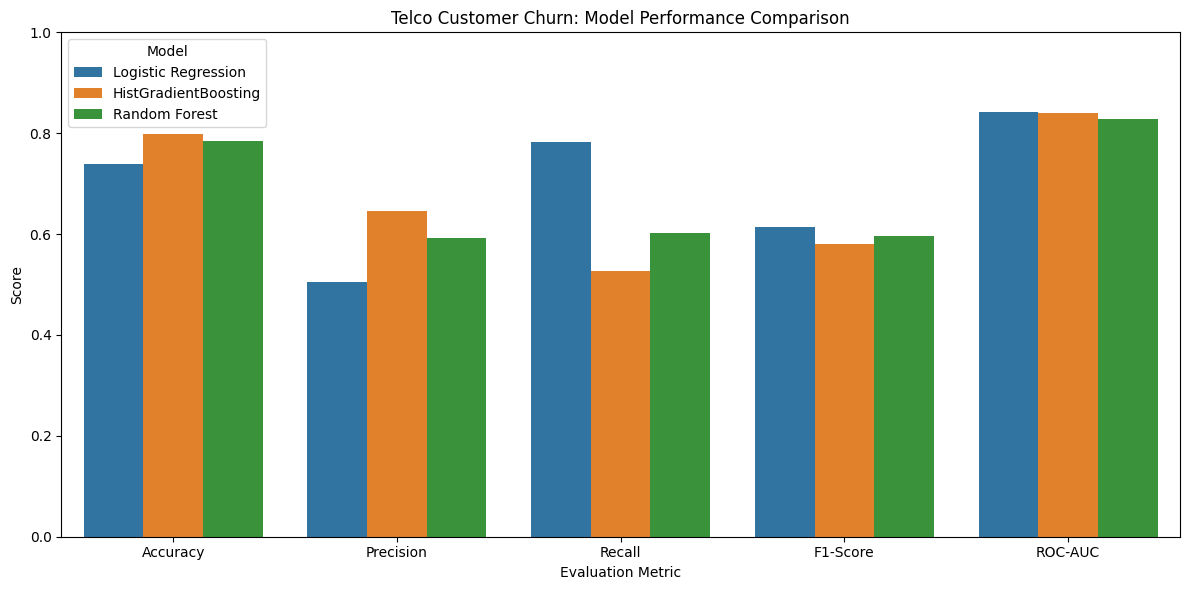

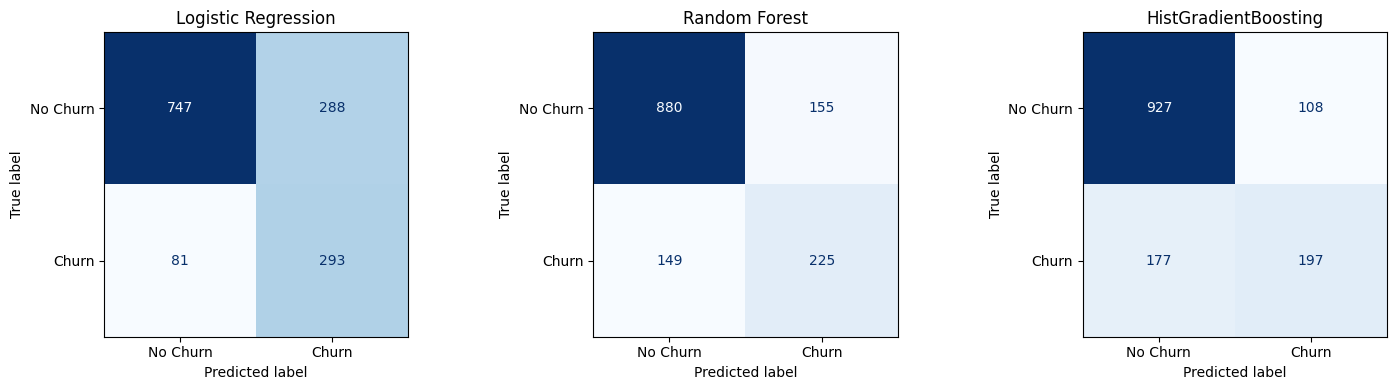

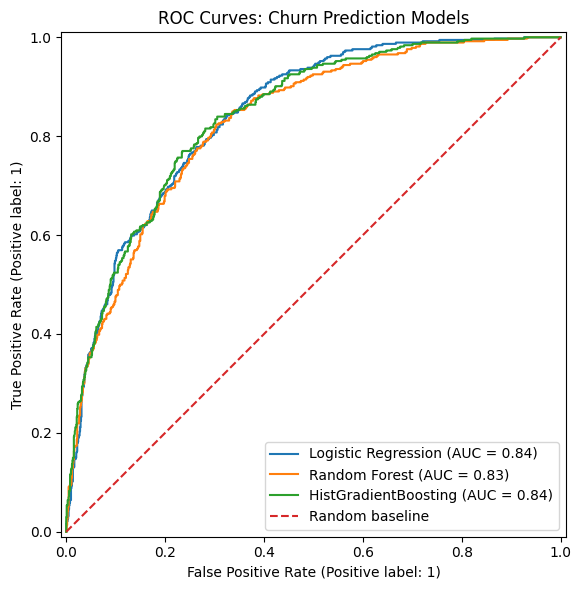


Top 15 Random Forest Features:
                            Feature  Importance
                        num__tenure    0.129734
                  num__TotalCharges    0.129350
                num__MonthlyCharges    0.103938
       cat__Contract_Month-to-month    0.085975
             cat__OnlineSecurity_No    0.045556
             cat__Contract_Two year    0.043711
                cat__TechSupport_No    0.036059
   cat__InternetService_Fiber optic    0.034981
cat__PaymentMethod_Electronic check    0.031070
               cat__OnlineBackup_No    0.017464
             cat__Contract_One year    0.015382
           cat__PaperlessBilling_No    0.013963
           cat__InternetService_DSL    0.013697
                 num__SeniorCitizen    0.013666
                   cat__gender_Male    0.013520


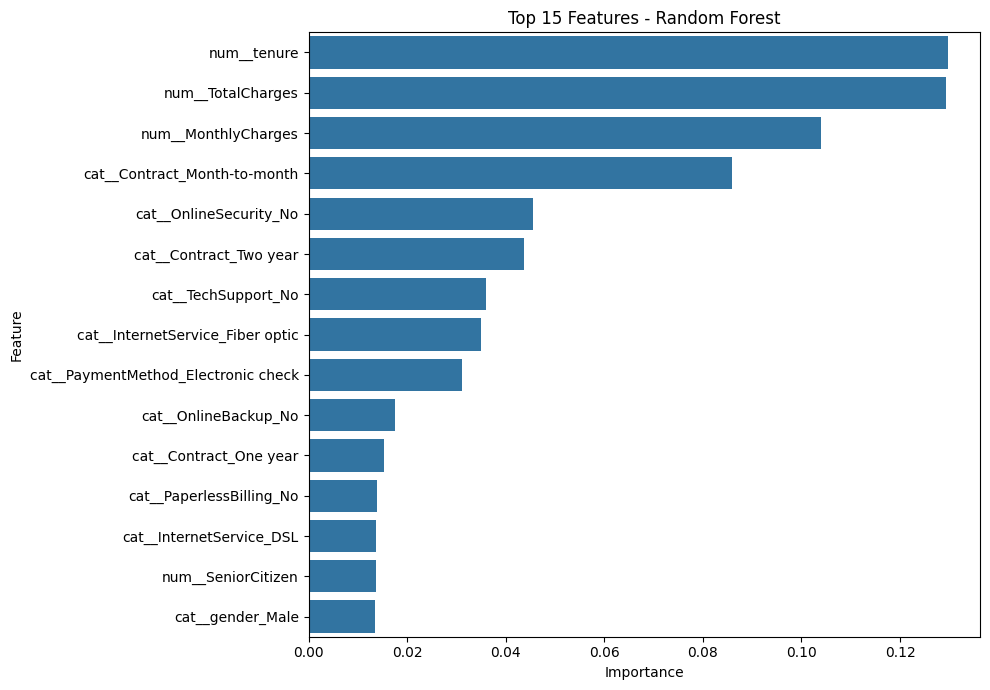


Sample Customer Prediction
Predicted churn: No
Estimated churn probability: 11.55%

PROJECT COMPLETED SUCCESSFULLY!


In [3]:

# ============================================================
# TELCO CUSTOMER CHURN PREDICTION
# Models: Logistic Regression, Random Forest,
#         HistGradientBoosting
# ============================================================

import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# ------------------------------------------------------------
# 1. LOAD DATASET
# ------------------------------------------------------------

# Download the CSV from Kaggle and place it in your project folder.
FILE_PATH = "/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv"



df = pd.read_csv(FILE_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())

# ------------------------------------------------------------
# 2. DATA EXPLORATION
# ------------------------------------------------------------

print("\nDataset information:")
df.info()

print("\nMissing values before cleaning:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nChurn distribution:")
print(df["Churn"].value_counts())

# ------------------------------------------------------------
# 3. DATA CLEANING
# ------------------------------------------------------------

# Remove duplicate records, if any.
df = df.drop_duplicates().copy()

# Customer ID is an identifier, not a predictive feature.
df = df.drop(columns=["customerID"], errors="ignore")

# Convert TotalCharges to numeric.
# Blank strings become NaN and will be imputed later.
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Separate features and target.
X = df.drop(columns=["Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

if y.isnull().any():
    raise ValueError("Unexpected values found in the Churn column.")

print("\nChurn target encoded: No = 0, Yes = 1")
print("Features shape:", X.shape)

# Identify numerical and categorical columns.
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("\nNumerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

# ------------------------------------------------------------
# 4. TRAIN-TEST SPLIT
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# ------------------------------------------------------------
# 5. PREPROCESSING
# ------------------------------------------------------------

# Numerical columns:
# Fill missing values with median and standardize.
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical columns:
# Fill missing values with the most frequent category
# and convert categories into numeric indicator columns.
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# ------------------------------------------------------------
# 6. DEFINE MACHINE LEARNING MODELS
# ------------------------------------------------------------

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.08,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    )
}

# ------------------------------------------------------------
# 7. TRAIN AND EVALUATE ALL MODELS
# ------------------------------------------------------------

results = []
trained_models = {}
predictions = {}
probabilities = {}

for name, model in models.items():

    print("\n" + "=" * 60)
    print("Training:", name)
    print("=" * 60)

    # HistGradientBoosting needs dense input.
    # Other models can use the sparse encoded matrix.
    if name == "HistGradientBoosting":
        from sklearn.preprocessing import FunctionTransformer

        dense_preprocessor = ColumnTransformer(
            transformers=[
                ("num", numeric_transformer, numeric_features),
                ("cat", Pipeline(steps=[
                    ("imputer", SimpleImputer(
                        strategy="most_frequent"
                    )),
                    ("encoder", OneHotEncoder(
                        handle_unknown="ignore",
                        sparse_output=False
                    ))
                ]), categorical_features)
            ],
            sparse_threshold=0
        )

        pipeline = Pipeline(steps=[
            ("preprocessor", dense_preprocessor),
            ("model", model)
        ])
    else:
        pipeline = Pipeline(steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ])

    start_time = time.time()

    pipeline.fit(X_train, y_train)

    training_time = time.time() - start_time

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    trained_models[name] = pipeline
    predictions[name] = y_pred
    probabilities[name] = y_prob

    # Evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )
    roc_auc = roc_auc_score(y_test, y_prob)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": roc_auc,
        "Training Time (sec)": training_time
    })

    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    print(f"ROC-AUC:   {roc_auc:.4f}")
    print(f"Training time: {training_time:.2f} seconds")

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["No Churn", "Churn"],
        zero_division=0
    ))

# ------------------------------------------------------------
# 8. COMPARE MODEL PERFORMANCE
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="ROC-AUC", ascending=False
).reset_index(drop=True)

print("\n" + "=" * 75)
print("FINAL MODEL COMPARISON")
print("=" * 75)

print(results_df.round(4).to_string(index=False))

# Save results to CSV.
results_df.to_csv("model_comparison_results.csv", index=False)
print("\nSaved: model_comparison_results.csv")

# Select the best model based on ROC-AUC.
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("\nBest model by ROC-AUC:", best_model_name)

# ------------------------------------------------------------
# 9. VISUALIZE METRIC COMPARISON
# ------------------------------------------------------------

metrics = [
    "Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"
]

results_long = results_df.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_long,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Telco Customer Churn: Model Performance Comparison")
plt.ylim(0, 1)
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.legend(title="Model")
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=300)
plt.show()

# ------------------------------------------------------------
# 10. CONFUSION MATRICES
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, name in zip(axes, models.keys()):
    cm = confusion_matrix(
        y_test, predictions[name], labels=[0, 1]
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Churn", "Churn"]
    ).plot(ax=ax, cmap="Blues", colorbar=False)

    ax.set_title(name)

plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=300)
plt.show()

# ------------------------------------------------------------
# 11. ROC CURVE COMPARISON
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 6))

for name in models.keys():
    RocCurveDisplay.from_predictions(
        y_test,
        probabilities[name],
        name=name,
        ax=ax
    )

ax.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
ax.set_title("ROC Curves: Churn Prediction Models")
ax.legend()
plt.tight_layout()
plt.savefig("roc_curves.png", dpi=300)
plt.show()

# ------------------------------------------------------------
# 12. FEATURE IMPORTANCE - RANDOM FOREST
# ------------------------------------------------------------

rf_pipeline = trained_models["Random Forest"]

encoded_names = rf_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

rf_importances = rf_pipeline.named_steps[
    "model"
].feature_importances_

importance_df = pd.DataFrame({
    "Feature": encoded_names,
    "Importance": rf_importances
}).sort_values(by="Importance", ascending=False)

print("\nTop 15 Random Forest Features:")
print(importance_df.head(15).to_string(index=False))

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features - Random Forest")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=300)
plt.show()

# ------------------------------------------------------------
# 13. SAMPLE CUSTOMER PREDICTION
# ------------------------------------------------------------

sample_customer = X_test.iloc[[0]]

predicted_churn = best_model.predict(sample_customer)[0]
churn_probability = best_model.predict_proba(
    sample_customer
)[0, 1]

print("\nSample Customer Prediction")
print("Predicted churn:", "Yes" if predicted_churn == 1 else "No")
print(f"Estimated churn probability: {churn_probability:.2%}")

print("\nPROJECT COMPLETED SUCCESSFULLY!")
